In [6]:
!pip install -q -U qwen-asr "datasets[audio]<4.0" jiwer soundfile librosa "pandas<3"

In [7]:
import pandas, datasets, jiwer, transformers, torch
from qwen_asr import Qwen3ASRModel
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

print("pandas", pandas.__version__, "| datasets", datasets.__version__, "| transformers", transformers.__version__)
print("GPU :", torch.cuda.get_device_name(0))
login(token=UserSecretsClient().get_secret("hf_token"))

I0000 00:00:1793827900.716078      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


pandas 2.3.3 | datasets 3.6.0 | transformers 4.57.6
GPU : Tesla T4


In [8]:
import os, io, re, gc, time, sqlite3, random
import numpy as np, pandas as pd, torch, jiwer, soundfile as sf
from collections import Counter
from datasets import load_dataset, Audio

SEED = 0
DB_PATH = "/kaggle/working/darija_asr.db" if os.path.isdir("/kaggle/working") else "darija_asr.db"

# --- règles de la base ---
MIN_DUR, MAX_DUR = 0.5, 30.0
VAL_FRACTION = 0.05
MIN_WORDS_LEAK = 3
DODA_TEST_IDX = list(range(1000, 2000)) + list(range(5000, 6000))   # à vérifier sur la fiche DODa

# --- évaluation (T4) ---
N_TEST_PER_SOURCE = 200
BATCH_SIZE = 8                   # mettre 4 si erreur mémoire avec le 1.7B
LANGUAGE = "Arabic"              # la darija n'est pas proposée comme langue on force l'arabe
MODELS = {
    "Qwen3-ASR-0.6B": "Qwen/Qwen3-ASR-0.6B",
    "Qwen3-ASR-1.7B": "Qwen/Qwen3-ASR-1.7B",
}
DTYPE = torch.float16            # le T4 ne gère pas bien le bfloat16
print(torch.cuda.get_device_name(0), DTYPE)

AR_DIGITS = str.maketrans("٠١٢٣٤٥٦٧٨٩۰۱۲۳۴۵۶۷۸۹", "01234567890123456789")

def norm(t):
    t = (t or "").translate(AR_DIGITS)
    t = re.sub(r"[\u064B-\u0652\u0640]", "", t)      # diacritiques + tatweel
    t = re.sub("[\u0622\u0623\u0625]", "\u0627", t)  # أ إ آ -> ا
    t = t.replace("\u0649", "\u064A").replace("\u0629", "\u0647")  # ى->ي ، ة->ه
    t = re.sub(r"[^\w\s]", " ", t)                   # ponctuation
    return re.sub(r"\s+", " ", t).strip()

print(norm("أنا غادي نمشي للمدرسة، ٣ د الصباح!"))

Tesla T4 torch.float16
انا غادي نمشي للمدرسه 3 د الصباح


In [9]:
doda      = load_dataset("atlasia/DODa-audio-dataset", split="train")
adi_train = load_dataset("adiren7/darija_speech_to_text", split="train")
adi_val   = load_dataset("adiren7/darija_speech_to_text", split="validation")

SOURCES = {                      # nom -> (dataset, colonne du texte)
    "doda":          (doda,      "darija_Arab_new"),
    "adiren7_train": (adi_train, "text"),
    "adiren7_val":   (adi_val,   "text"),
}
LABELS = {"doda": "DODa (parole lue)", "adiren7_val": "adiren7 (spontanée)"}
for k, (d, c) in SOURCES.items():
    print(k, len(d), "clips | colonne texte :", c)

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00005.parquet:   0%|          | 0.00/333M [00:00<?, ?B/s]

data/train-00001-of-00005.parquet:   0%|          | 0.00/279M [00:00<?, ?B/s]

data/train-00002-of-00005.parquet:   0%|          | 0.00/237M [00:00<?, ?B/s]

data/train-00003-of-00005.parquet:   0%|          | 0.00/226M [00:00<?, ?B/s]

data/train-00004-of-00005.parquet:   0%|          | 0.00/210M [00:00<?, ?B/s]

... (5 outputs left out)

data/validation-00000-of-00001.parquet:   0%|          | 0.00/313M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/4336 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1065 [00:00<?, ? examples/s]

doda 12743 clips | colonne texte : darija_Arab_new
adiren7_train 4336 clips | colonne texte : text
adiren7_val 1065 clips | colonne texte : text


In [10]:
LATIN = re.compile(r"[A-Za-z]")
DODA_TEST_SET = set(DODA_TEST_IDX)

if os.path.exists(DB_PATH):
    os.remove(DB_PATH)
db = sqlite3.connect(DB_PATH)
db.executescript("""
CREATE TABLE clips(
  clip_id TEXT PRIMARY KEY, source TEXT, row_idx INTEGER,
  text_raw TEXT, text_norm TEXT, duration REAL, n_words INTEGER,
  has_latin INTEGER, is_empty INTEGER, split TEXT, drop_reason TEXT);
CREATE TABLE predictions(
  clip_id TEXT, model TEXT, hyp_raw TEXT, hyp_norm TEXT,
  w_err INTEGER, w_ref INTEGER, c_err INTEGER, c_ref INTEGER,
  hyp_has_latin INTEGER, kw_total INTEGER, kw_hit INTEGER, lat REAL, dur REAL,
  PRIMARY KEY(clip_id, model));
CREATE TABLE lexicon(
  word TEXT PRIMARY KEY, lang TEXT, count INTEGER, arabic_form TEXT, note TEXT);
""")

def audio_duration(a):
    try:
        if a.get("bytes"):
            return float(sf.info(io.BytesIO(a["bytes"])).duration)
        if a.get("path"):
            return float(sf.info(a["path"]).duration)
    except Exception:
        pass
    return None

def initial_split(name, i):
    if name == "doda":
        return "test" if i in DODA_TEST_SET else "train"
    return "test" if name == "adiren7_val" else "train"

def add_source(name):
    ds, col = SOURCES[name]
    d = ds.select_columns(["audio", col]).cast_column("audio", Audio(decode=False))
    rows = []
    for i, ex in enumerate(d):
        raw = ex[col] or ""
        txt = norm(raw)
        rows.append((f"{name}_{i}", name, i, raw, txt, audio_duration(ex["audio"]),
                     len(txt.split()), int(bool(LATIN.search(raw))), int(len(txt) == 0),
                     initial_split(name, i), None))
    db.executemany("INSERT INTO clips VALUES (?,?,?,?,?,?,?,?,?,?,?)", rows)
    db.commit()
    print(name, ":", len(rows), "clips ajoutés", flush=True)

for name in SOURCES:
    add_source(name)

doda : 12743 clips ajoutés
adiren7_train : 4336 clips ajoutés
adiren7_val : 1065 clips ajoutés


In [11]:
q = lambda s: pd.read_sql(s, db)

print("Clips par source et par split :")
display(q("""SELECT source, split, COUNT(*) AS clips,
             ROUND(SUM(duration)/3600.0, 2) AS heures
             FROM clips GROUP BY source, split"""))

print("Qualité des références :")
display(q("""SELECT source, COUNT(*) AS n, SUM(is_empty) AS vides,
             SUM(has_latin) AS avec_latin, ROUND(100.0*AVG(has_latin), 1) AS pct_latin,
             SUM(duration IS NULL) AS duree_inconnue,
             ROUND(MIN(duration), 1) AS d_min, ROUND(AVG(duration), 1) AS d_moy,
             ROUND(MAX(duration), 1) AS d_max
             FROM clips GROUP BY source"""))

print("Exemples de références contenant des lettres latines :")
display(q("SELECT source, text_raw FROM clips WHERE has_latin = 1 LIMIT 10"))

Clips par source et par split :


,source,split,clips,heures
0,adiren7_train,train,4336,34.47
1,adiren7_val,test,1065,8.50
2,doda,test,2000,1.54
3,doda,train,10743,7.92


Qualité des références :


,source,n,vides,avec_latin,pct_latin,duree_inconnue,d_min,d_moy,d_max
0,adiren7_train,4336,0,2,0.0,0,1.8,28.6,30.0
1,adiren7_val,1065,0,1,0.1,0,11.3,28.7,30.0
2,doda,12743,22,0,0.0,0,0.8,2.7,11.6


Exemples de références contenant des lettres latines :


,source,text_raw
0,adiren7_train,الكتب. اه. كتب اه عربية anglay. ضروري الديكسون يكون عندو. اه فافلام. اه اه ديال اه ديال اه ديال اه ديال الميوزيك ديال اي حاجة. عمر راسك قلب على قلب كتب وغيطلع لك ما لا يعد ويحصى من الكلمات حاول تعمر راسك ودير جمل واللعيبات انا واحد القضية يكون مثلا تيسمع شي موسيقى بالإنجليزية تعجبو شي كلمة يمشي يترجمها
1,adiren7_train,ولكن الجودة باقا هي هي لا ضروري تبارك الله شناهي الميزة ديال ديال سيدي قاسم قلنا عليه. حنا العسل ديالنا حنا اصلا المنطقة ديال سيدي قاسم او منطقة الغرب بصفة عامة ومعروفة بالكاليبتوس والليمون والاعشاب يعني حنا لا يعلى علينا اهاه يعني الليمون ديالنا مميز الكاليبتوس مميز ualité ديالو ديما كتكون وحنا راه الجهة ديال الغرب كلها يعني النسبة ديال العسل را اكبر نسبة فالمغرب
2,adiren7_val,مازوينش مازوينش انا مازوينش مازوينش ماتاتحسش مزيان يعني ماشي ماشي ماشي مرتاح يعني ماشي مرتاح ماشي ماشي مرتاح نفسيا يعني. اهاه. متنحسش براسي مرتاح ماشي عزيز يمكن كنقول lage يمكن كنقول بزاف ديال الحويجات زادو لي ما عندي فواحد يمكن زادوا التزامات زادوا بزاف ديال الحويجات زاد زائد فميداني انك باش تحافظ على واحد النجاح اللي عطاه لك الله


In [12]:
MAX_DUR = 30.5

# 1) règles de nettoyage (train/val) ; pour le test, seules les références vides sont écartées
db.execute("""
UPDATE clips SET drop_reason = CASE
  WHEN is_empty = 1 THEN 'texte_vide'
  WHEN split != 'test' AND has_latin = 1 THEN 'lettres_latines'
  WHEN split != 'test' AND duration IS NOT NULL AND duration < ? THEN 'trop_court'
  WHEN split != 'test' AND duration IS NOT NULL AND duration > ? THEN 'trop_long'
  ELSE NULL END
""", (MIN_DUR, MAX_DUR))
db.commit()
display(q("""SELECT source, COALESCE(drop_reason, 'GARDÉ') AS statut, COUNT(*) AS clips
             FROM clips GROUP BY source, statut ORDER BY source, clips DESC"""))

# 2) fuite : phrases du test présentes dans le train
before = q("""SELECT COUNT(*) AS n FROM clips
              WHERE split='train' AND drop_reason IS NULL AND n_words >= %d
                AND text_norm IN (SELECT text_norm FROM clips WHERE split='test')""" % MIN_WORDS_LEAK).n[0]
db.execute("""UPDATE clips SET drop_reason='doublon_test'
              WHERE split='train' AND drop_reason IS NULL AND n_words >= ?
                AND text_norm IN (SELECT text_norm FROM clips WHERE split='test')""", (MIN_WORDS_LEAK,))
db.commit()
print("Clips du train retirés car leur phrase est dans le test :", before)

# 3) validation tirée au hasard dans le train gardé
rng = random.Random(SEED)
ids = [r[0] for r in db.execute("SELECT clip_id FROM clips WHERE split='train' AND drop_reason IS NULL ORDER BY clip_id")]
rng.shuffle(ids)
val_ids = ids[: int(len(ids) * VAL_FRACTION)]
db.executemany("UPDATE clips SET split='val' WHERE clip_id=?", [(i,) for i in val_ids])
db.commit()

# 4) vérification
check = q("""SELECT COUNT(*) AS n FROM clips
             WHERE split IN ('train','val') AND drop_reason IS NULL AND n_words >= %d
               AND text_norm IN (SELECT text_norm FROM clips WHERE split='test')""" % MIN_WORDS_LEAK).n[0]
print("Fuites restantes (doit être 0) :", check)
display(q("""SELECT split, COUNT(*) AS clips, ROUND(SUM(duration)/3600.0, 2) AS heures
             FROM clips WHERE drop_reason IS NULL GROUP BY split"""))

,source,statut,clips
0,adiren7_train,GARDÉ,4334
1,adiren7_train,lettres_latines,2
2,adiren7_val,GARDÉ,1065
3,doda,GARDÉ,12721
4,doda,texte_vide,22


Clips du train retirés car leur phrase est dans le test : 24
Fuites restantes (doit être 0) : 0


,split,clips,heures
0,test,3061,10.04
1,train,14284,40.11
2,val,751,2.24


In [13]:
cnt = Counter()
for (t,) in db.execute("SELECT text_norm FROM clips WHERE split='train' AND drop_reason IS NULL"):
    cnt.update(t.split())
db.executemany("INSERT OR REPLACE INTO lexicon(word, lang, count) VALUES (?, 'darija_frequent', ?)",
               cnt.most_common(200))
db.commit()
LEX = {w for (w,) in db.execute("SELECT word FROM lexicon")}
display(q("SELECT word, count FROM lexicon ORDER BY count DESC LIMIT 15"))

test_df = q("""SELECT clip_id, source, row_idx, text_norm, duration FROM clips
               WHERE split='test' AND drop_reason IS NULL""")
parts = [g.sample(min(N_TEST_PER_SOURCE, len(g)), random_state=SEED)
         for _, g in test_df.groupby("source")]
test_sample = pd.concat(parts).reset_index(drop=True)
display(test_sample.groupby("source").size().rename("clips de test"))

,word,count
0,ديال,4776
1,من,3502
2,ما,3499
3,لي,3473
4,واحد,3454
5,في,3371
6,اللي,3066
7,علي,3042
8,هاد,2466
9,يعني,2445


source
adiren7_val    200
doda           200
Name: clips de test, dtype: int64

In [14]:
from qwen_asr import Qwen3ASRModel

def sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def edit_counts(ref, hyp):
    """erreurs (substitutions + suppressions + insertions) au niveau mots et lettres"""
    w_ref, c_ref = len(ref.split()), len(ref)
    if not hyp.strip():
        return w_ref, w_ref, c_ref, c_ref
    w = jiwer.process_words(ref, hyp)
    c = jiwer.process_characters(ref, hyp)
    return (w.substitutions + w.deletions + w.insertions, w_ref,
            c.substitutions + c.deletions + c.insertions, c_ref)

def kw_counts(ref, hyp):
    ref_kw = Counter(w for w in ref.split() if w in LEX)
    hyp_c = Counter(hyp.split())
    return sum(ref_kw.values()), sum(min(c, hyp_c[w]) for w, c in ref_kw.items())

def run_model(name, repo):
    model = Qwen3ASRModel.from_pretrained(
        repo, dtype=DTYPE, device_map="cuda:0",
        max_inference_batch_size=BATCH_SIZE, max_new_tokens=512)
    out_rows = []
    for src in sorted(test_sample.source.unique()):
        sub = test_sample[test_sample.source == src].reset_index(drop=True)
        ds = SOURCES[src][0].select(sub.row_idx.tolist()).select_columns(["audio"])
        ds = ds.cast_column("audio", Audio(sampling_rate=16000))
        for i in range(0, len(sub), BATCH_SIZE):
            batch = ds[i:i + BATCH_SIZE]
            audios = [(a["array"].astype(np.float32), a["sampling_rate"]) for a in batch["audio"]]
            durs = [len(a) / sr for a, sr in audios]
            sync(); t0 = time.perf_counter()
            res = model.transcribe(audio=audios, language=[LANGUAGE] * len(audios))
            sync(); dt = time.perf_counter() - t0
            for j, r in enumerate(res):
                row = sub.iloc[i + j]
                hyp_raw = r.text or ""
                hyp = norm(hyp_raw)
                we, wr, ce, cr = edit_counts(row.text_norm, hyp)
                kt, kh = kw_counts(row.text_norm, hyp)
                out_rows.append((row.clip_id, name, hyp_raw, hyp, we, wr, ce, cr,
                                 int(bool(LATIN.search(hyp_raw))), kt, kh, dt / len(durs), durs[j]))
        print(f"{name} | {LABELS.get(src, src)} terminé", flush=True)
    db.executemany("INSERT OR REPLACE INTO predictions VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?)", out_rows)
    db.commit()
    del model; gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

already = {m for (m,) in db.execute("SELECT DISTINCT model FROM predictions")}
for name, repo in MODELS.items():
    if name in already:
        print(name, ": déjà en base, on passe")
        continue
    run_model(name, repo)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.88G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


preprocessor_config.json:   0%|          | 0.00/330 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

... (19 outputs left out)

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for

Qwen3-ASR-1.7B | adiren7 (spontanée) terminé


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151645 for

Qwen3-ASR-1.7B | DODa (parole lue) terminé


,Modèle,Dataset,Clips,WER %,CER %,Sorties avec lettres latines %,Mots fréquents retrouvés %,RTF
2,Qwen3-ASR-1.7B,DODa (parole lue),200,73.50,27.30,0.5,39.3,0.083
0,Qwen3-ASR-0.6B,DODa (parole lue),200,79.61,32.56,0.5,30.7,0.069
3,Qwen3-ASR-1.7B,adiren7 (spontanée),200,76.44,35.68,15.0,48.3,0.060
1,Qwen3-ASR-0.6B,adiren7 (spontanée),200,82.56,39.65,13.5,39.8,0.067


,Clips,WER %,CER %,Sorties avec lettres latines %,Mots fréquents retrouvés %,RTF,Score (WER+CER)/2
Modèle,,,,,,,
Qwen3-ASR-1.7B,400,76.21,35.07,7.8,47.6,0.062,55.64
Qwen3-ASR-0.6B,400,82.34,39.14,7.0,39.1,0.067,60.74


Meilleur modèle : Qwen3-ASR-1.7B


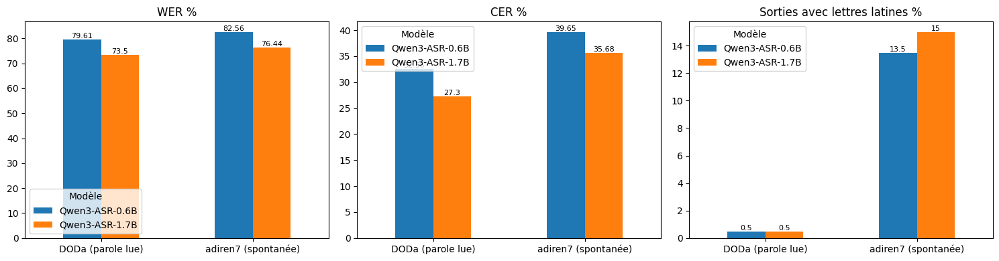

,Modèle,Durée,Clips,WER %
0,Qwen3-ASR-0.6B,< 5 s,188,79.47
1,Qwen3-ASR-0.6B,5 à 15 s,13,82.35
2,Qwen3-ASR-0.6B,> 15 s,199,82.54
3,Qwen3-ASR-1.7B,< 5 s,188,73.11
4,Qwen3-ASR-1.7B,5 à 15 s,13,75.40
5,Qwen3-ASR-1.7B,> 15 s,199,76.44


In [15]:
P = q("""SELECT p.*, c.source, c.text_norm AS ref
         FROM predictions p JOIN clips c USING (clip_id)""")
P["Dataset"] = P.source.map(lambda s: LABELS.get(s, s))

def summarize(g):
    return {
        "Clips": len(g),
        "WER %": round(100 * g.w_err.sum() / g.w_ref.sum(), 2),
        "CER %": round(100 * g.c_err.sum() / g.c_ref.sum(), 2),
        "Sorties avec lettres latines %": round(100 * g.hyp_has_latin.mean(), 1),
        "Mots fréquents retrouvés %": round(100 * g.kw_hit.sum() / max(g.kw_total.sum(), 1), 1),
        "RTF": round(g.lat.sum() / g.dur.sum(), 3),
    }

rows = [{"Modèle": m, "Dataset": d, **summarize(g)} for (m, d), g in P.groupby(["model", "Dataset"])]
res = pd.DataFrame(rows).sort_values(["Dataset", "WER %"])
res.to_csv("resultats_comparaison.csv", index=False)
display(res)

rows = [{"Modèle": m, **summarize(g)} for m, g in P.groupby("model")]
score = pd.DataFrame(rows).set_index("Modèle")
score["Score (WER+CER)/2"] = ((score["WER %"] + score["CER %"]) / 2).round(2)
score = score.sort_values("Score (WER+CER)/2")
display(score)
BEST = score.index[0]
print("Meilleur modèle :", BEST)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["WER %", "CER %", "Sorties avec lettres latines %"]):
    res.pivot(index="Dataset", columns="Modèle", values=metric).plot.bar(ax=ax, rot=0)
    ax.set_title(metric); ax.set_xlabel("")
    for c in ax.containers:
        ax.bar_label(c, fontsize=8)
plt.tight_layout(); plt.savefig("comparaison_modeles.png", dpi=150); plt.show()

P["Durée"] = pd.cut(P.dur, [0, 5, 15, 10000], labels=["< 5 s", "5 à 15 s", "> 15 s"])
rows = [{"Modèle": m, "Durée": b, "Clips": len(g),
         "WER %": round(100 * g.w_err.sum() / g.w_ref.sum(), 2)}
        for (m, b), g in P.groupby(["model", "Durée"], observed=True)]
display(pd.DataFrame(rows))

In [16]:
def top_errors(g, k=15):
    c = Counter()
    for ref, hyp in zip(g.ref, g.hyp_norm):
        if not hyp.strip():
            c.update(ref.split()); continue
        out = jiwer.process_words(ref, hyp)
        for ch in out.alignments[0]:
            if ch.type in ("substitute", "delete"):
                c.update(out.references[0][ch.ref_start_idx:ch.ref_end_idx])
    return c.most_common(k)

for (m, d), g in P.groupby(["model", "Dataset"]):
    print(f"\n=== {m} | {d} ===")
    print("Mots les plus ratés :", top_errors(g))

print("\nExemples de sorties contenant des lettres latines :")
display(P[P.hyp_has_latin == 1][["model", "Dataset", "ref", "hyp_raw"]].head(10))


=== Qwen3-ASR-0.6B | DODa (parole lue) ===
Mots les plus ratés : [('ديال', 17), ('واش', 15), ('شي', 13), ('بزاف', 11), ('ما', 10), ('هادشي', 10), ('غادي', 10), ('هاد', 8), ('راه', 7), ('باش', 7), ('ديالي', 6), ('ليا', 6), ('ليك', 6), ('تا', 6), ('دابا', 6)]

=== Qwen3-ASR-0.6B | adiren7 (spontanée) ===
Mots les plus ratés : [('ديال', 178), ('لي', 158), ('ما', 97), ('هاد', 94), ('اللي', 87), ('واحد', 79), ('باش', 79), ('كاين', 72), ('راه', 66), ('اه', 60), ('علي', 58), ('هو', 55), ('من', 51), ('غادي', 51), ('شي', 51)]

=== Qwen3-ASR-1.7B | DODa (parole lue) ===
Mots les plus ratés : [('واش', 15), ('شي', 15), ('ديال', 14), ('هادشي', 10), ('بزاف', 9), ('ما', 8), ('هاد', 7), ('راه', 7), ('باش', 7), ('ليا', 6), ('تا', 6), ('دابا', 6), ('علي', 6), ('في', 5), ('لي', 5)]

=== Qwen3-ASR-1.7B | adiren7 (spontanée) ===
Mots les plus ratés : [('لي', 163), ('ديال', 134), ('باش', 81), ('كاين', 73), ('هاد', 72), ('اه', 63), ('راه', 63), ('اللي', 62), ('شي', 55), ('ديالو', 48), ('هادي', 47), ('ما', 4

,model,Dataset,ref,hyp_raw
10,Qwen3-ASR-0.6B,adiren7 (spontanée),كحله الله يخليك انا مزيان تصحح ليا را الخدمه ديالي مزيان وحنا هادشي اللي بغيناك بغيناك تفيدنا فهاد المشكل ديال الما علاش وصلنا ليه لان السيد اللي السيد رئيس الحكومه ملي قلتي قبل كان كذلك عنصر في الحكومه السابقه اه عضو في الحكومه السابقه كان كيسير الفلاحه اييه النتائج دالفلاحه ها هي وباش نجحات الفلاحه المحطه ديال التحليه الماء فالشتوكه اللي اليوم مبقاتش كدير عين الفلاحه ولات كتعطي حتي للمدينه ديال اكادير,حلى كنت رعب مزيان سحلي و مزيان سحلي الله خليك أنا مزيان سحلي راح أخذ بدي لياد مزيان و إحنا هالشيء اللي بنك بنكتفيدنا هالمشكلة اللي معناش وصنعه لأن السيد الق صيضاء استحكومة مني قلت شيء قبل كان كذلك عنصر في الحكومة السابقة عضو في في الحكومة السابقة كان كسير الفيلا حياة إيج للفلاحة هي و بس شح الفلاحة الله خليك و بس شح الفلاحة و إحدى المعتاد الحياد الماء الشوكا لليوم كetchup الدلع الفلاحة و لفترة ضحت المدينة الأقديس و
16,Qwen3-ASR-0.6B,adiren7 (spontanée),الاخير يوم الجمعه الماضي لما وقع التنصيص علي ضروره اعتماد فضائل والاجتهاد المنفتح البناء في ظل عدم السماح بتحليل ارامل ولا بتحريم حلال التنصيص علي فضائل الاعتدال والاجتهاد المنفتح البناء فيه الاعتدال تنقولو فالسياق المغربي الوسطي والاعتدال هذا منهجنا كذلك الاجتهاد المنفتح الاستاذه بوزيد شارت ليه لا منفتح ماشي فقط يعني علي المذاهب الاخري,الأخري يوم الجمعة لم أضِل موقع تنسيس على ضروة تيماد فضائل اعتداء والجihad المنفتي الحبنا في غلي عدم السمح بتحليل حرامي ولا بتحليل بيتحريمي حلل شنم شنم معنى تنسيس على فضائل اعتداء والجihad المنفتي الحبنا في اعتداء اللي كان يقول في السياق المغريبي وسطي والعتداء الهدا منهجنا كذلك الجihad المنفتي ح وكان سادة بوزيد شاطر للمنفتيح ماشي فقط يعني على المدهي بالأخ
63,Qwen3-ASR-0.6B,adiren7 (spontanée),الموضه الحاليه تيريحو اه تيريحو وحنا محتاجين يلاه كنا علي الضغط النساء فوقت ما لقينا الفرصه نفوجو علي نفوسنا نفوجو علي غير فحال هاكا باللوينات درتي جوج ديال وحدات حتي هي هرستي خرجت لي كاينه انا خرجت,بالذات ال الحياكة هي ل ل كولر natural ل كولر pastel ل كولر سيريح. ااا نحن نحتاج ريح لكننا سنقوم بصنعها. ونقوم بصنعها. طريقة حياكة نيسا فوق سماكنا فرصة. فرصة ناسا. نفوجة ناسا. نفوجة للحرب. نسيرفيس حلاكة لوي نات pastel pastel. تجين القديرة تجي جوجل ناب وحدة تحسيب ل كولر pastel. ل كولر pastel. هرس تجيب ل كولر بخرجت ل كولر ل كيناب. donc أنا خرجت ل روز.
71,Qwen3-ASR-0.6B,adiren7 (spontanée),فماشي فقط الشركه كتبيع الخشب راه صافي مزيان لا كتبيع الخشب ميكونش عندها الديون مع بنوك ربويه ومكتكونش حاطه طيب مزيان مكتاخد كريدي مكتعطي كريدي ها مزيان هادي كنت درت اكتتاب احتاجت من بعد كان ديالها ممتاز هادشي من بعد كيوقع شناهو هداك ديال شركه الخشب انا نبيعهم لك ونتا تبيعهم لفلان وفلان نبيعهم لفلان وفلان رجعهم لفلان وملي تجي غادي نسمعو اخبار سيئه نديرو نبيعوها علي المكشوف وتتعاود تزيد تهبط,فا مشي فقط شركة كزبيل خشب راسا في مزيان لا كزبيل خشب ممكنش عندها ديوين مع بونو قريب ديوين ممكنش على الطاولة سبرينج طيب مزيان ممكن تشوف تقرير دي ممكن تأكير ها مزيان هذه درس كتاب يحتاج كنس بحصان ت financing بعد كنس بحصان ديزاجون دي لا ممتازة جي بعد كيو قاع لمشي سووندرخ مشي سووندرخ ناوي هذا كيزاجون دي الشركة تخشب أنا بيعملك ونتجيبهم فلان فلان بيعمل فلان فلان بيعمل فلان وملجي لا ينسمعوا أخبار سي أندرو لافانتا ديكو في عنبوا علمك شوف وتعود زيت برقى
82,Qwen3-ASR-0.6B,adiren7 (spontanée),وفيه الهدا ولكن منطوق مزيان وما فيه تا شي مشكل قال لك يعني حسن بدرجات من انك تدوي حسن من تلتميه الف درجه او نعطيو مثال ديال هندي ديالو كتسمع كتسمع بحال هكا الوزير شوف اش دار اه شوف شحال ديال البشر كيتصنت ليه يعني بمعني حيدو العقده ديال من بدماغكم بمعني الحاجه الوحيده اللي غتجيب لك,الروفي الهدا ولكن من الطاقم زين و ما في شيء مشكير. يقولك it's far far better than يعني حسن الظاراجات من أنا كدوب أونغلام صرطات بريدات طططططططططط. حسن التلثميت الفظاراجة. و نعطوه ميتشل لل CEO لل Google. هني. لونغلي دي يلوك تسمع ترى يلعب كتسمع حلاقة. يعععني شو شو شو هذه البشر كي تصنع لي. يعني بمعنى. حيد الله قد يلخصون بدماغكم. بمعنى. الحشوة واحدة لقيبلك لخ.
84,Qwen3-ASR-0.6B,adiren7 (spontanée),هاد كنت باغي ندوزو لبزاف ديال الناس الناس الكبار لي عندهم كاين واعرين تبارك الله راه نتا وانا كضحنا فرصه اننا نتلاقاو مع ناس الادمغه ديالهم ولكن فاش كتقوليه دير فيديو ولوحو كيقولك معدي مندير داك

In [17]:
import pandas as pd
from IPython.display import Audio as IPAudio
pd.set_option("display.max_colwidth", None)     # affiche les textes en entier

def show_clip(clip_id):
    c = q(f"SELECT source, row_idx, text_raw FROM clips WHERE clip_id='{clip_id}'").iloc[0]
    ex = SOURCES[c.source][0].select([int(c.row_idx)]).cast_column("audio", Audio(sampling_rate=16000))[0]
    arr = ex["audio"]["array"]
    print("Clip      :", clip_id, "| durée :", round(len(arr) / 16000, 1), "s")
    print("Référence :", c.text_raw)
    for m, h in q(f"SELECT model, hyp_raw FROM predictions WHERE clip_id='{clip_id}' ORDER BY model").values:
        print(f"{m:15s} :", h)
    display(IPAudio(arr, rate=16000))
    print("-" * 70)

# 1) clips où un modèle a écrit en lettres latines
latin_ids = P[P.hyp_has_latin == 1].drop_duplicates("clip_id").clip_id.tolist()
print(len(latin_ids), "clips avec sortie en lettres latines")
for cid in latin_ids[:5]:
    show_clip(cid)

# 2) clips les plus mal transcrits par le meilleur modèle
W = P[P.model == BEST].copy()
W["wer_clip"] = W.w_err / W.w_ref
for cid in W.sort_values("wer_clip", ascending=False).clip_id.head(5):
    show_clip(cid)

42 clips avec sortie en lettres latines
Clip      : adiren7_val_824 | durée : 30.0 s
Référence : كحلة الله يخليك انا مزيان تصحح ليا را الخدمة ديالي مزيان وحنا هادشي اللي بغيناك بغيناك تفيدنا فهاد المشكل ديال الما علاش وصلنا ليه? لأن السيد اللي السيد رئيس الحكومة ملي قلتي قبل كان كذلك عنصر في الحكومة السابقة اه عضو في الحكومة السابقة كان كيسير الفلاحة اييه النتائج دالفلاحة ها هي وباش نجحات الفلاحة المحطة ديال التحلية الماء فالشتوكة اللي اليوم مبقاتش كدير عين الفلاحة ولات كتعطي حتى للمدينة ديال اكادير
Qwen3-ASR-0.6B  : حلى كنت رعب مزيان سحلي و مزيان سحلي الله خليك أنا مزيان سحلي راح أخذ بدي لياد مزيان و إحنا هالشيء اللي بنك بنكتفيدنا هالمشكلة اللي معناش وصنعه لأن السيد الق صيضاء استحكومة مني قلت شيء قبل كان كذلك عنصر في الحكومة السابقة عضو في في الحكومة السابقة كان كسير الفيلا حياة إيج للفلاحة هي و بس شح الفلاحة الله خليك و بس شح الفلاحة و إحدى المعتاد الحياد الماء الشوكا لليوم كetchup الدلع الفلاحة و لفترة ضحت المدينة الأقديس و
Qwen3-ASR-1.7B  : عم زيان سحلي يا والله زيان سحلي يا ألفين 

----------------------------------------------------------------------
Clip      : adiren7_val_382 | durée : 30.0 s
Référence : الاخير يوم الجمعة الماضي لما وقع التنصيص على ضرورة اعتماد فضائل والاجتهاد المنفتح البناء في ظل عدم السماح بتحليل ارامل ولا بتحريم حلال التنصيص على فضائل الاعتدال والاجتهاد المنفتح البناء فيه الاعتدال تنقولو فالسياق المغربي الوسطي والاعتدال هذا منهجنا كذلك الاجتهاد المنفتح الأستاذة بوزيد شارت ليه لا منفتح ماشي فقط يعني على المذاهب الأخرى
Qwen3-ASR-0.6B  : الأخري يوم الجمعة لم أضِل موقع تنسيس على ضروة تيماد فضائل اعتداء والجihad المنفتي الحبنا في غلي عدم السمح بتحليل حرامي ولا بتحليل بيتحريمي حلل شنم شنم معنى تنسيس على فضائل اعتداء والجihad المنفتي الحبنا في اعتداء اللي كان يقول في السياق المغريبي وسطي والعتداء الهدا منهجنا كذلك الجihad المنفتي ح وكان سادة بوزيد شاطر للمنفتيح ماشي فقط يعني على المدهي بالأخ
Qwen3-ASR-1.7B  : الأخر يوم الجمعة. لما ذي لم مواقع تنصيص على ضرورة اعتماد فضائل اعتدال والاجتهاد المُنفتح البنا في ريلي عدم السماح بتحليل حرامي ولا بتحليل بت

----------------------------------------------------------------------
Clip      : adiren7_val_689 | durée : 30.0 s
Référence : الموضة الحالية تيريحو اه تيريحو وحنا محتاجين يلاه كنا على الضغط النساء فوقت ما لقينا الفرصة نفوجو على نفوسنا نفوجو على غير فحال هاكا باللوينات درتي جوج ديال وحدات حتى هي هرستي خرجت لي كاينة انا خرجت
Qwen3-ASR-0.6B  : بالذات ال الحياكة هي ل ل كولر natural ل كولر pastel ل كولر سيريح. ااا نحن نحتاج ريح لكننا سنقوم بصنعها. ونقوم بصنعها. طريقة حياكة نيسا فوق سماكنا فرصة. فرصة ناسا. نفوجة ناسا. نفوجة للحرب. نسيرفيس حلاكة لوي نات pastel pastel. تجين القديرة تجي جوجل ناب وحدة تحسيب ل كولر pastel. ل كولر pastel. هرس تجيب ل كولر بخرجت ل كولر ل كيناب. donc أنا خرجت ل روز.
Qwen3-ASR-1.7B  : المواد الحالية هي للكوLOURات شغال، للكوLOURات باستل، للكوLOURات تريحه. نحتاج يريلك نسالك. نروح. نخصص. نبيس على. شو نيسا؟ فوق سمال كنا فرصة. فشنا نروح. فوجوا على الخصنا. فوجوا على الخرب. ان السيرفيس حلقة بلونات بستل بستل. تين القدي. درتي جوجلنا. واحدة تفتح سيب للكوLOURات بستل. للكوLOURا

----------------------------------------------------------------------
Clip      : adiren7_val_561 | durée : 30.0 s
Référence : فماشي فقط الشركة كتبيع الخشب راه صافي مزيان لا كتبيع الخشب ميكونش عندها الديون مع بنوك ربوية ومكتكونش حاطة طيب مزيان مكتاخد كريدي مكتعطي كريدي ها مزيان هادي كنت درت اكتتاب احتاجت من بعد كان ديالها ممتاز هادشي من بعد كيوقع شناهو? هداك ديال شركة الخشب انا نبيعهم لك ونتا تبيعهم لفلان وفلان نبيعهم لفلان وفلان رجعهم لفلان وملي تجي غادي نسمعو اخبار سيئة نديرو نبيعوها على المكشوف وتتعاود تزيد تهبط
Qwen3-ASR-0.6B  : فا مشي فقط شركة كزبيل خشب راسا في مزيان لا كزبيل خشب ممكنش عندها ديوين مع بونو قريب ديوين ممكنش على الطاولة سبرينج طيب مزيان ممكن تشوف تقرير دي ممكن تأكير ها مزيان هذه درس كتاب يحتاج كنس بحصان ت financing بعد كنس بحصان ديزاجون دي لا ممتازة جي بعد كيو قاع لمشي سووندرخ مشي سووندرخ ناوي هذا كيزاجون دي الشركة تخشب أنا بيعملك ونتجيبهم فلان فلان بيعمل فلان فلان بيعمل فلان وملجي لا ينسمعوا أخبار سي أندرو لافانتا ديكو في عنبوا علمك شوف وتعود زيت برقى
Qwen3-ASR-1.7

----------------------------------------------------------------------
Clip      : adiren7_val_142 | durée : 30.0 s
Référence : وفيه الهدا ولكن منطوق مزيان وما فيه تا شي مشكل. قال لك يعني حسن بدرجات من انك تدوي حسن من تلتمية الف درجة. او نعطيو مثال ديال هندي ديالو كتسمع كتسمع بحال هكا الوزير شوف اش دار. اه. شوف شحال ديال البشر كيتصنت ليه. يعني بمعنى حيدو العقدة ديال من بدماغكم بمعنى الحاجة الوحيدة اللي غتجيب لك
Qwen3-ASR-0.6B  : الروفي الهدا ولكن من الطاقم زين و ما في شيء مشكير. يقولك it's far far better than يعني حسن الظاراجات من أنا كدوب أونغلام صرطات بريدات طططططططططط. حسن التلثميت الفظاراجة. و نعطوه ميتشل لل CEO لل Google. هني. لونغلي دي يلوك تسمع ترى يلعب كتسمع حلاقة. يعععني شو شو شو هذه البشر كي تصنع لي. يعني بمعنى. حيد الله قد يلخصون بدماغكم. بمعنى. الحشوة واحدة لقيبلك لخ.
Qwen3-ASR-1.7B  : الرفيل هذا ولكن من الطقم زين وما في كشي مشكير قالك it's far far better than يعني حسن بالدرجات من أنا كدوب انجلام صوتها بريز تات تات تات تات تات حسن بالكلت مية ألف درجة ونعتقم يتكلم ديل سي إيو

----------------------------------------------------------------------
Clip      : adiren7_val_989 | durée : 20.0 s
Référence : فعومي
Qwen3-ASR-0.6B  : بسكلياً، الت د م ب دينتى
Qwen3-ASR-1.7B  : بشكل عام، لم تتلق DMP أي طلب من الشركات أو المختبرات المذكورة أعلاه. ومع ذلك، سيتم منح ترخيص الطوارئ للاستثمارات في اللقاحات وتقديم الإذن لحملة التطعيم ضد كوفيد-19 لتخفيض المنحنى من الحالات والوفيات الشديدة. هل تفهم؟ ضع هذا في اعتبارك. النتيجة النهائية للقاحات الوطنية.


----------------------------------------------------------------------
Clip      : adiren7_val_681 | durée : 30.0 s
Référence : وهابنز بالسفر بيك كوفيد بروتين. كوفيد ناينتين
Qwen3-ASR-0.6B  : In handling, this vaccine requires a stringent cold chain. In fact, these strict storage conditions are required for both Pfizer and Moderna's COVID-19 vaccine. Now, I think we are familiar with the conventional procedure as well as the new generation of vaccines. Let's move on to the viral vector vaccine. What happens is they use an unrelated harmless virus that has been modified to act as a delivery system to carry genetic material that codes for a specific COVID protein. It is not the virus that causes COVID-19, but a different harmless.
Qwen3-ASR-1.7B  : في التعامل، هذه اللقاحات تتطلب سلسلة باردة صارمة. في الواقع، هذه الظروف الاحتفاظ الصارمة مطلوبة لكل من لقاح فايزر و Moderna كوفيد 19. الآن، أعتقد أننا مألوفون بالإجراء التقليدي وكذلك الجيل الجديد من اللقاحات. دعونا ننتقل إلى لقاحات الفيروسات. 

----------------------------------------------------------------------
Clip      : adiren7_val_942 | durée : 30.0 s
Référence : السي السباعي الرسالة انك شكرتينا نجوى كوكوس اخر تدخل اخر تدخل في التواصل الحكومي كاين اللي كيقول هاد الحكومة وقالها السي
Qwen3-ASR-0.6B  : الجو كوسس السفيع متألق متألق جو كوسس السفيع مروعة الواحد لطيف الحقيقة الحقيقة أنك شكورتينا جلوية بالعمات وتم أنتم وتم أنتم بالإنجازات وتم أنتم بالإنجازات وتم حقية حياة أخيسة تقول أخيسة تقول أخيسة تقول الجو كوسس أخيسة تقول في التواصل الحكومي كنيكي يقوله الحكومة وجالس
Qwen3-ASR-1.7B  : لي جوا، جوا كوس، جوا كوس سباع، متل، متل، جوا كوس، جوا كوس سباع، سؤال واحد، لابد حقي، تير رسالة، حقا، حقا، نشكر تينا، قولوا تيبا العمل، قولوا تم إنك، وتم إنك بالإنجازات، قولوا الإنجازات والمحطات الجميلة، أخسة دخل، أخسة دخل، أخسة دخل، جوا كوس، أخسة دخل في تواصل حكومي، كلك يقول الحكومة، وجلس.


----------------------------------------------------------------------
Clip      : adiren7_val_453 | durée : 28.9 s
Référence : جر منو صدقاتو مثلا ولا مكتخربقكمش نتوما كنتو بوحديتو تا هو فيه عالم شناهوا ديالنا حنا ديالنا هو نخلقو ديالنا هو اللي غادي يسهلوا حياة المواطن هادا هو ديالنا الى كانت
Qwen3-ASR-0.6B  : زور بنظرتك. أوكي. وعندما يكون business مثلاً أو business model. مكتوب كم ش. جو مكتوب في في la finance. ابقي الوجستي. الوجستي هو الحديث تجاه. حلم. حلم. في الحقيقة نقول الميتيديان. رأسي بالا في ناس. هنالك ميتيديان هو نخلقوا ديمتية. هنالك ميتيديان هو. اشغلي ذي اكتيبيتي لغدي سهل حياة الموارد. هذول الميتيديان. إلى كانت.
Qwen3-ASR-1.7B  : زور من أصل خاص. okay. وطONG que business مثلًا أو la business model. ما كتشرح بكمش؟ جو ما كتوف في la finance. أخير logistique أو logistique واحدي توت تهوى في عالم. عالم واحدي شو؟ logistique عالم. in fact ناوي لو métierين. رأسي برا finance. إحنا لو métierين نهوا نخلق دمتي. okay. إحنا لو métierين نهوا نبحثي ده activités لغادي سهلوا حياة المواطن. ده لو m

----------------------------------------------------------------------
Clip      : doda_1229 | durée : 1.6 s
Référence : وصلتي
Qwen3-ASR-0.6B  : وصلكي
Qwen3-ASR-1.7B  : وصل شيء.


----------------------------------------------------------------------
